# Bài toán 3 — Đánh giá mô hình

## 7. Đánh giá và so sánh kết quả

### 7.1. Phạm vi và chỉ số đánh giá

- Dữ liệu phát triển: 04/07/2012–01/07/2021 (3.285 ngày), gồm ba lượt validation theo thời gian, mỗi lượt 548 ngày.
- Tập đánh giá cuối: 02/07/2021–31/12/2022 (548 ngày). Tất cả dự báo test chỉ dùng thông tin đến 01/07/2021.
- Hai mục tiêu: Revenue và COGS. MAE và RMSE tính theo triệu đơn vị tiền tệ/ngày; R² không có đơn vị. MAE, RMSE càng nhỏ càng tốt; R² càng lớn càng tốt (có thể âm).
- Hybrid Ensemble là mô hình dự báo chính. Để đối chiếu với Hybrid, xác định phương pháp có MAE validation thấp nhất bằng trung bình ba lượt, riêng cho từng mục tiêu.

Đọc dự báo từ `02_mo_hinh.ipynb`. Đối với các đối chứng chưa có dự báo test trong tệp, dùng đúng hàm từ notebook 02 để dự báo từ tập phát triển. Không tinh chỉnh tham số theo test. Kiến trúc Hybrid đã từng được nghiên cứu với dữ liệu đến năm 2022, nên kết quả đánh giá cuối mang tính hồi cứu, không phải kiểm định độc lập hoàn toàn.

In [9]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sales_path = Path("data/raw/sales.csv")
start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
project_root = next(
    (folder for folder in (start, *start.parents) if (folder / sales_path).is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Không tìm thấy data/raw/sales.csv. Hãy đặt notebook trong dự án "
        "hoặc trỏ RETAIL_ANALYTICS_ROOT về thư mục gốc."
    )

prediction_path = project_root / "data/model/du_bao/forecast_predictions.csv"
if not prediction_path.is_file():
    raise FileNotFoundError("Chạy 02_mo_hinh.ipynb để tạo forecast_predictions.csv.")

predictions = pd.read_csv(
    prediction_path, parse_dates=["Date", "TrainEnd"], float_precision="round_trip",
)
targets = ["Revenue", "COGS"]

observed = pd.read_csv(
    project_root / sales_path, usecols=["Date", *targets], parse_dates=["Date"],
).set_index("Date").sort_index()[targets]
if not observed.index.is_unique:
    raise ValueError("sales.csv có ngày trùng. Kiểm tra lại ở 01_du_lieu.ipynb.")

contest_name = "Baseline cuộc thi"
fixed_name = "Mùa vụ, mức gốc cố định"


def prediction_frame(rows):
    return rows.set_index("Date")[targets].sort_index()


def test_forecast_for(method):
    return prediction_frame(predictions.loc[
        predictions["Split"].eq("test") & predictions["Method"].eq(method)
    ])


def evaluate(actual, forecast):
    pd.testing.assert_index_equal(actual.index, forecast.index)
    pd.testing.assert_index_equal(actual.columns, forecast.columns)
    if not np.isfinite(forecast.to_numpy(dtype=float)).all():
        raise ValueError("Dự báo có giá trị thiếu hoặc không hữu hạn.")
    actual = actual.astype(float) / 1_000_000
    error = forecast.astype(float) / 1_000_000 - actual
    squared_error = error.pow(2)
    variation = (actual - actual.mean()).pow(2).sum()
    return pd.DataFrame({
        "MAE": error.abs().mean(),
        "RMSE": np.sqrt(squared_error.mean()),
        "R²": 1 - squared_error.sum() / variation.where(variation > 0),
    }).rename_axis("Chỉ tiêu")

weekday_name = "Mùa vụ mức gốc cố định + hiệu ứng thứ"
hybrid_name = "Hybrid Ensemble phân rã và phân khúc"
method_order = ["Naive", "Trung bình 28 ngày", "Theo thứ trong tuần", "ETS (A,N,N)",
                "ARIMA(1,1,1)", "Hồi quy tuyến tính", "Hồi quy tuyến tính + mùa vụ",
                contest_name, fixed_name, weekday_name, hybrid_name]
dev_end = pd.Timestamp("2021-07-01")
final_dates = pd.date_range("2021-07-02", "2022-12-31", name="Date")
assert len(final_dates) == 548
assert observed.index.equals(pd.date_range("2012-07-04", "2022-12-31", name="Date"))
assert np.isfinite(observed.to_numpy(dtype=float)).all()
required_cols = {"Split", "Fold", "TrainEnd", "Date", "Method", *targets}
assert required_cols.issubset(predictions.columns)
assert not predictions.duplicated(["Split", "Fold", "Method", "Date"]).any()
assert np.isfinite(predictions[targets].to_numpy(dtype=float)).all()
assert (predictions.Date > predictions.TrainEnd).all()
validation = predictions.loc[predictions.Split.eq("validation")].copy()
assert set(validation.Method) == set(method_order), "Cần chạy notebook 02 bản cập nhật đủ 11 mô hình."
fold_windows = {1:("2016-12-31","2018-07-01"), 2:("2018-07-02","2019-12-31"), 3:("2020-01-01","2021-07-01")}
assert set(validation.Fold) == set(fold_windows)
for fold_id, (lo, hi) in fold_windows.items():
    block = validation.loc[validation.Fold.eq(fold_id)]
    assert set(block.Method) == set(method_order)
    for method, rows in block.groupby("Method"):
        assert prediction_frame(rows).index.equals(pd.date_range(lo, hi, name="Date"))
        assert rows.TrainEnd.eq(pd.Timestamp(lo) - pd.Timedelta(days=1)).all()
test_rows = predictions.loc[predictions.Split.eq("test")]
assert test_rows.TrainEnd.eq(dev_end).all() and test_rows.Fold.eq(0).all()
assert {contest_name, fixed_name, weekday_name, hybrid_name}.issubset(test_rows.Method.unique())
for method, rows in test_rows.groupby("Method"):
    assert prediction_frame(rows).index.equals(final_dates)
print(f"Đã kiểm tra {len(validation):,} dòng validation và {len(test_rows):,} dòng test từ notebook 02.")

Đã kiểm tra 18,084 dòng validation và 2,740 dòng test từ notebook 02.


### 7.2. So sánh trên ba lượt validation

Mỗi lượt có cùng độ dài 548 ngày. Tính từng chỉ số theo lượt rồi lấy trung bình, không trộn dữ liệu giữa các mốc huấn luyện.

In [10]:
score_rows = []
validation = predictions.loc[predictions["Split"].eq("validation")]
for (fold_id, method), rows in validation.groupby(["Fold", "Method"], sort=False):
    forecast = prediction_frame(rows)
    score_rows.append(evaluate(observed.loc[forecast.index], forecast).assign(Fold=fold_id, Method=method))

validation_scores = pd.concat(score_rows).reset_index().rename(columns={"Method": "Phương pháp"})
summary = validation_scores.groupby(["Phương pháp", "Chỉ tiêu"])[["MAE", "RMSE", "R²"]].mean()
display(summary.unstack("Chỉ tiêu").reindex(validation["Method"].unique()).round(6))
validation_best = summary["MAE"].unstack("Chỉ tiêu").idxmin().reindex(targets)
display(validation_best.rename("MAE validation thấp nhất"))
print("MAE của từng lượt:")
display(validation_scores.pivot(index="Phương pháp", columns=["Fold", "Chỉ tiêu"], values="MAE").reindex(method_order).round(6))
print("Kết quả đứng đầu validation theo MAE")
for target, method in validation_best.items():
    print(f"{target}: {method} (MAE = {summary.loc[(method,target), 'MAE']:.6f})")

MAE                RMSE            \
Chỉ tiêu                                   COGS   Revenue      COGS   Revenue   
Phương pháp                                                                     
Naive                                  3.039196  3.123752  3.403556  3.602729   
Trung bình 28 ngày                     2.504237  3.091022  3.063588  3.783946   
Theo thứ trong tuần                    2.524641  3.105716  3.103259  3.818654   
ETS (A,N,N)                            3.040859  3.125365  3.404879  3.603377   
ARIMA(1,1,1)                           2.604919  3.171440  3.121155  3.810979   
Hồi quy tuyến tính                     2.137894  2.459694  2.509923  2.904722   
Hồi quy tuyến tính + mùa vụ            1.617387  1.857832  1.910089  2.228297   
Baseline cuộc thi                      1.194796  1.375094  1.484706  1.726717   
Mùa vụ, mức gốc cố định                1.048035  1.211976  1.324369  1.548465   
Mùa vụ mức gốc cố định + hiệu ứng thứ  1.018286  1.181767  1.303751  1.530487   
Hybrid Ensemble phân rã và phân khúc   1.131490  1.298505  1.442573  1.666757   

                                             R²            
Chỉ tiêu                                   COGS   Revenue  
Phương pháp                                                
Naive                                 -3.966718 -2.673824  
Trung bình 28 ngày                    -2.268331 -2.470649  
Theo thứ trong tuần                   -2.356966 -2.545044  
ETS (A,N,N)                           -3.967740 -2.674225  
ARIMA(1,1,1)                          -2.683193 -2.865467  
Hồi quy tuyến tính                    -0.918923 -0.826963  
Hồi quy tuyến tính + mùa vụ           -0.336865 -0.284755  
Baseline cuộc thi                      0.194541  0.255643  
Mùa vụ, mức gốc cố định                0.373543  0.414212  
Mùa vụ mức gốc cố định + hiệu ứng thứ  0.383709  0.422047  
Hybrid Ensemble phân rã và phân khúc   0.031016  0.086207

Chỉ tiêu
Revenue    Mùa vụ mức gốc cố định + hiệu ứng thứ
COGS       Mùa vụ mức gốc cố định + hiệu ứng thứ
Name: MAE validation thấp nhất, dtype: object

MAE của từng lượt:


Fold                                          1                   2            \
Chỉ tiêu                                Revenue      COGS   Revenue      COGS   
Phương pháp                                                                     
Naive                                  2.526219  2.353035  5.528297  5.603376   
Trung bình 28 ngày                     2.663029  2.137478  4.943464  4.101598   
Theo thứ trong tuần                    2.673263  2.153199  4.942131  4.103231   
ETS (A,N,N)                            2.531058  2.358025  5.528297  5.603376   
ARIMA(1,1,1)                           2.506262  2.076133  5.522790  4.567502   
Hồi quy tuyến tính                     2.541232  2.164442  3.036246  2.619723   
Hồi quy tuyến tính + mùa vụ            1.464118  1.228043  2.514072  2.193028   
Baseline cuộc thi                      1.454122  1.215790  2.069960  1.875545   
Mùa vụ, mức gốc cố định                1.180078  0.966912  1.796897  1.615207   
Mùa vụ mức gốc cố định + hiệu ứng thứ  1.104845  0.904133  1.791294  1.597619   
Hybrid Ensemble phân rã và phân khúc   0.912259  0.796726  2.457179  2.148548   

Fold                                          3            
Chỉ tiêu                                Revenue      COGS  
Phương pháp                                                
Naive                                  1.316741  1.161176  
Trung bình 28 ngày                     1.666573  1.273636  
Theo thứ trong tuần                    1.701753  1.317493  
ETS (A,N,N)                            1.316741  1.161176  
ARIMA(1,1,1)                           1.485269  1.171122  
Hồi quy tuyến tính                     1.801604  1.629517  
Hồi quy tuyến tính + mùa vụ            1.595305  1.431090  
Baseline cuộc thi                      0.601199  0.493053  
Mùa vụ, mức gốc cố định                0.658954  0.561986  
Mùa vụ mức gốc cố định + hiệu ứng thứ  0.649164  0.553106  
Hybrid Ensemble phân rã và phân khúc   0.526077  0.449195

Kết quả đứng đầu validation theo MAE
Revenue: Mùa vụ mức gốc cố định + hiệu ứng thứ (MAE = 1.181767)
COGS: Mùa vụ mức gốc cố định + hiệu ứng thứ (MAE = 1.018286)


### 7.3. Chuẩn bị dự báo test cho đầy đủ 11 phương pháp

Notebook 02 lưu toàn bộ dự báo validation và các dự báo test chính. Nếu thiếu dự báo test của một số đối chứng, dùng lại nguyên hàm của notebook 02 dưới đây. Không ghi đè `forecast_predictions.csv`, không dùng giá trị thực tế test để khớp mô hình; không chạy lại Hybrid.

In [11]:
import sys
from time import perf_counter
import warnings

import statsmodels
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | NumPy {np.__version__} | statsmodels {statsmodels.__version__}")

contest_name = "Baseline cuộc thi"
fixed_name = "Mùa vụ, mức gốc cố định"
mean_name = "Trung bình 28 ngày"


def repeat_level(level, dates):
    return pd.DataFrame(
        np.tile(level.to_numpy(dtype=float), (len(dates), 1)),
        index=dates, columns=level.index,
    )

def predict_naive(train, dates):
    return repeat_level(train.iloc[-1], dates)

def predict_mean_28(train, dates):
    return repeat_level(train.tail(28).mean(), dates)

def predict_weekday(train, dates):
    recent = train.tail(28)
    weekday = recent.groupby(recent.index.dayofweek).mean()
    forecast = weekday.reindex(dates.dayofweek)
    forecast.index = dates
    return forecast

def predict_ets(train, dates):
    forecast = pd.DataFrame(index=dates, columns=train.columns, dtype=float)
    for target in train.columns:
        history = train[target].astype(float).asfreq("D") / 1_000_000
        fitted = SimpleExpSmoothing(history, initialization_method="estimated").fit()
        estimate = fitted.forecast(len(dates))
        pd.testing.assert_index_equal(estimate.index, dates, check_names=False)
        forecast[target] = estimate.to_numpy(dtype=float) * 1_000_000
    return forecast

def predict_arima(train, dates):
    forecast = pd.DataFrame(index=dates, columns=train.columns, dtype=float)
    for target in train.columns:
        history = train[target].astype(float).asfreq("D") / 1_000_000
        with warnings.catch_warnings():
            # Statsmodels dùng điểm khởi tạo bằng 0 khi ước lượng ban đầu không phù hợp.
            warnings.filterwarnings(
                "ignore", message=r"Non-(stationary|invertible) starting .*", category=UserWarning,
            )
            fitted = ARIMA(history, order=(1, 1, 1)).fit()
        if not fitted.mle_retvals["converged"]:
            raise RuntimeError(f"ARIMA không hội tụ cho {target}, mốc {train.index[-1]:%d/%m/%Y}.")
        estimate = fitted.forecast(len(dates))
        pd.testing.assert_index_equal(estimate.index, dates, check_names=False)
        forecast[target] = estimate.to_numpy(dtype=float) * 1_000_000
    return forecast

def predict_trend(train, dates):
    origin = train.index[0]
    train_days = (train.index - origin).days.to_numpy()
    future_days = (dates - origin).days.to_numpy()
    slope, intercept = np.polyfit(train_days, train.to_numpy(dtype=float), 1)
    forecast = pd.DataFrame(
        intercept + future_days[:, None] * slope, index=dates, columns=train.columns,
    )
    return forecast

def predict_trend_with_seasonality(train, dates):
    trend = predict_trend(train, train.index.append(dates))
    residuals = train - trend.loc[train.index]
    seasonal = residuals.groupby([train.index.month, train.index.day]).mean()
    month_day = pd.MultiIndex.from_arrays([dates.month, dates.day])
    adjustment = seasonal.reindex(month_day).fillna(0.0)
    adjustment.index = dates
    return trend.loc[dates] + adjustment

def predict_contest_baseline(train, forecast_dates):
    years = train.index.year
    days_observed = train.groupby(years).size()
    days_in_year = pd.to_datetime(
        days_observed.index.astype(str) + "-12-31"
    ).dayofyear
    complete_years = days_observed.index[days_observed.eq(days_in_year)]

    # Tính mức gốc và tăng trưởng từ các năm đủ dữ liệu.
    annual_totals = train.groupby(years).sum().loc[complete_years]
    base_year = complete_years[-1]
    base_level = annual_totals.loc[base_year] / days_observed.loc[base_year]
    growth = (annual_totals.iloc[-1] / annual_totals.iloc[0]) ** (
        1 / (base_year - complete_years[0])
    )

    # Tính hệ số mùa vụ theo cặp tháng–ngày từ tập train.
    normalized = train.div(train.groupby(years).transform("mean"))
    seasonal = normalized.groupby([train.index.month, train.index.day]).mean()
    month_day = pd.MultiIndex.from_arrays([forecast_dates.month, forecast_dates.day])
    seasonal_factors = seasonal.reindex(month_day).fillna(1.0)
    seasonal_factors.index = forecast_dates

    years_ahead = (forecast_dates.year - base_year).to_numpy()
    growth_factors = growth.to_numpy() ** years_ahead[:, None]
    return seasonal_factors.mul(growth_factors).mul(base_level).round(2)

def predict_fixed_level_seasonal(train, forecast_dates):
    # Lấy trung bình ngày của năm đầy đủ gần nhất làm mức gốc.
    years = train.index.year
    days_observed = train.groupby(years).size()
    days_in_year = pd.to_datetime(
        days_observed.index.astype(str) + "-12-31"
    ).dayofyear
    complete_years = days_observed.index[days_observed.eq(days_in_year)]
    base_year = complete_years[-1]
    base_level = train.loc[str(base_year)].mean()

    # Tính hệ số mùa vụ cho từng cặp tháng–ngày từ tập train.
    normalized = train.div(train.groupby(years).transform("mean"))
    seasonal = normalized.groupby([train.index.month, train.index.day]).mean()
    month_day = pd.MultiIndex.from_arrays([forecast_dates.month, forecast_dates.day])
    factors = seasonal.reindex(month_day).fillna(1.0)
    factors.index = forecast_dates

    return factors.mul(base_level).round(2)

def predict_fixed_level_with_weekday(train, forecast_dates):
    base_forecast = predict_fixed_level_seasonal(train, forecast_dates)
    years = train.index.year
    normalized = train.astype(float).div(train.groupby(years).transform("mean"))
    ratios = []

    for year in years.unique():
        current_year = normalized.loc[years == year]
        other_years = normalized.loc[years != year]

        seasonal = other_years.groupby(
            [other_years.index.month, other_years.index.day]
        ).mean()

        dates = current_year.index
        month_day = pd.MultiIndex.from_arrays([dates.month, dates.day])
        reference = seasonal.reindex(month_day).set_axis(dates)
        ratios.append(current_year.div(reference))

    ratios = pd.concat(ratios)
    weekday_factors = ratios.groupby(ratios.index.dayofweek).median()
    weekday_factors = weekday_factors.div(weekday_factors.mean())

    adjustment = weekday_factors.reindex(forecast_dates.dayofweek)
    adjustment.index = forecast_dates
    return base_forecast.mul(adjustment).round(2)

Python 3.11.7 | pandas 2.2.3 | NumPy 2.4.6 | statsmodels 0.15.0


In [12]:
baseline_predictors = {
    "Naive": predict_naive, "Trung bình 28 ngày": predict_mean_28,
    "Theo thứ trong tuần": predict_weekday, "ETS (A,N,N)": predict_ets,
    "ARIMA(1,1,1)": predict_arima, "Hồi quy tuyến tính": predict_trend,
    "Hồi quy tuyến tính + mùa vụ": predict_trend_with_seasonality,
    contest_name: predict_contest_baseline, fixed_name: predict_fixed_level_seasonal,
    weekday_name: predict_fixed_level_with_weekday,
}
final_train = observed.loc[:dev_end, targets].copy()
assert len(final_train) == 3285 and final_train.index.max() < final_dates.min()
test_forecasts = {}
missing_methods = []
for method in method_order:
    if method in test_rows.Method.unique():
        forecast = test_forecast_for(method)
    else:
        missing_methods.append(method)
        forecast = baseline_predictors[method](final_train, final_dates)
    forecast = forecast.rename_axis("Date")
    pd.testing.assert_index_equal(forecast.index, final_dates)
    assert list(forecast.columns) == targets
    assert np.isfinite(forecast.to_numpy(dtype=float)).all()
    test_forecasts[method] = forecast
validation_reference = pd.DataFrame({
    target: test_forecasts[validation_best[target]][target] for target in targets
}, index=final_dates)
print(f"Đã chuẩn bị {len(test_forecasts)} mô hình × {len(final_dates)} ngày.")
print("Đối chứng cần chạy bổ sung:", missing_methods)
# Chỉ mở nhãn test để tính sai số sau khi dự báo đã hoàn tất.
test_actual = observed.loc[final_dates, targets].copy()
hybrid_test_forecast = test_forecasts[hybrid_name]
reference_test_forecast = test_forecasts[contest_name]

Đã chuẩn bị 11 mô hình × 548 ngày.
Đối chứng cần chạy bổ sung: ['Naive', 'Trung bình 28 ngày', 'Theo thứ trong tuần', 'ETS (A,N,N)', 'ARIMA(1,1,1)', 'Hồi quy tuyến tính', 'Hồi quy tuyến tính + mùa vụ']


### 7.4. Kết quả trên 548 ngày test

So sánh toàn bộ 11 phương pháp. MAE tổng hợp bên dưới là trung bình cộng MAE của Revenue và COGS, dùng để mô tả chung, không thay thế chỉ số từng mục tiêu. In đậm/đánh dấu mô hình có kết quả tốt nhất theo từng chỉ số.

In [13]:
test_metrics = pd.concat({method: evaluate(test_actual, pred) for method, pred in test_forecasts.items()}, names=["Phương pháp"])
for target in targets:
    table = test_metrics.xs(target, level="Chỉ tiêu").reindex(method_order)
    print(target, "— MAE/RMSE: triệu đơn vị tiền tệ/ngày")
    display(table.style.format(precision=6).highlight_min(subset=["MAE", "RMSE"], color="#d1fae5").highlight_max(subset=["R²"], color="#d1fae5"))
    print("Tốt nhất:", {metric: (table[metric].idxmax() if metric == "R²" else table[metric].idxmin()) for metric in table})
aggregate = test_metrics.groupby(level="Phương pháp", sort=False).mean().rename(columns={"MAE":"MAE trung bình", "RMSE":"RMSE trung bình", "R²":"R² trung bình"})
display(aggregate.sort_values("MAE trung bình").round(6))

Revenue — MAE/RMSE: triệu đơn vị tiền tệ/ngày


,MAE,RMSE,R²
Phương pháp,,,
Naive,2.350052,2.612375,-1.829557
Trung bình 28 ngày,1.668106,1.930552,-0.545292
Theo thứ trong tuần,1.677941,1.977492,-0.621351
"ETS (A,N,N)",2.350773,2.613077,-1.831079
"ARIMA(1,1,1)",1.980669,2.248001,-1.095272
Hồi quy tuyến tính,1.335208,1.632170,-0.104532
Hồi quy tuyến tính + mùa vụ,0.766511,1.113207,0.486194
Baseline cuộc thi,0.690395,0.959012,0.618675
"Mùa vụ, mức gốc cố định",0.595752,0.820935,0.720575


Tốt nhất: {'MAE': 'Hybrid Ensemble phân rã và phân khúc', 'RMSE': 'Hybrid Ensemble phân rã và phân khúc', 'R²': 'Hybrid Ensemble phân rã và phân khúc'}
COGS — MAE/RMSE: triệu đơn vị tiền tệ/ngày


,MAE,RMSE,R²
Phương pháp,,,
Naive,2.557864,2.777891,-3.127623
Trung bình 28 ngày,1.353520,1.603379,-0.375124
Theo thứ trong tuần,1.374837,1.658833,-0.471888
"ETS (A,N,N)",2.557427,2.777468,-3.126364
"ARIMA(1,1,1)",1.645779,1.886092,-0.902810
Hồi quy tuyến tính,1.116193,1.398557,-0.046236
Hồi quy tuyến tính + mùa vụ,0.644314,0.923152,0.544157
Baseline cuộc thi,0.678900,0.923072,0.544235
"Mùa vụ, mức gốc cố định",0.541723,0.752410,0.697184


Tốt nhất: {'MAE': 'Hybrid Ensemble phân rã và phân khúc', 'RMSE': 'Hybrid Ensemble phân rã và phân khúc', 'R²': 'Hybrid Ensemble phân rã và phân khúc'}


,MAE trung bình,RMSE trung bình,R² trung bình
Phương pháp,,,
Hybrid Ensemble phân rã và phân khúc,0.468741,0.648966,0.802569
Mùa vụ mức gốc cố định + hiệu ứng thứ,0.551821,0.765750,0.724083
"Mùa vụ, mức gốc cố định",0.568737,0.786672,0.708880
Baseline cuộc thi,0.684648,0.941042,0.581455
Hồi quy tuyến tính + mùa vụ,0.705413,1.018179,0.515175
Hồi quy tuyến tính,1.225701,1.515363,-0.075384
Trung bình 28 ngày,1.510813,1.766966,-0.460208
Theo thứ trong tuần,1.526389,1.818162,-0.546620
"ARIMA(1,1,1)",1.813224,2.067046,-0.999041


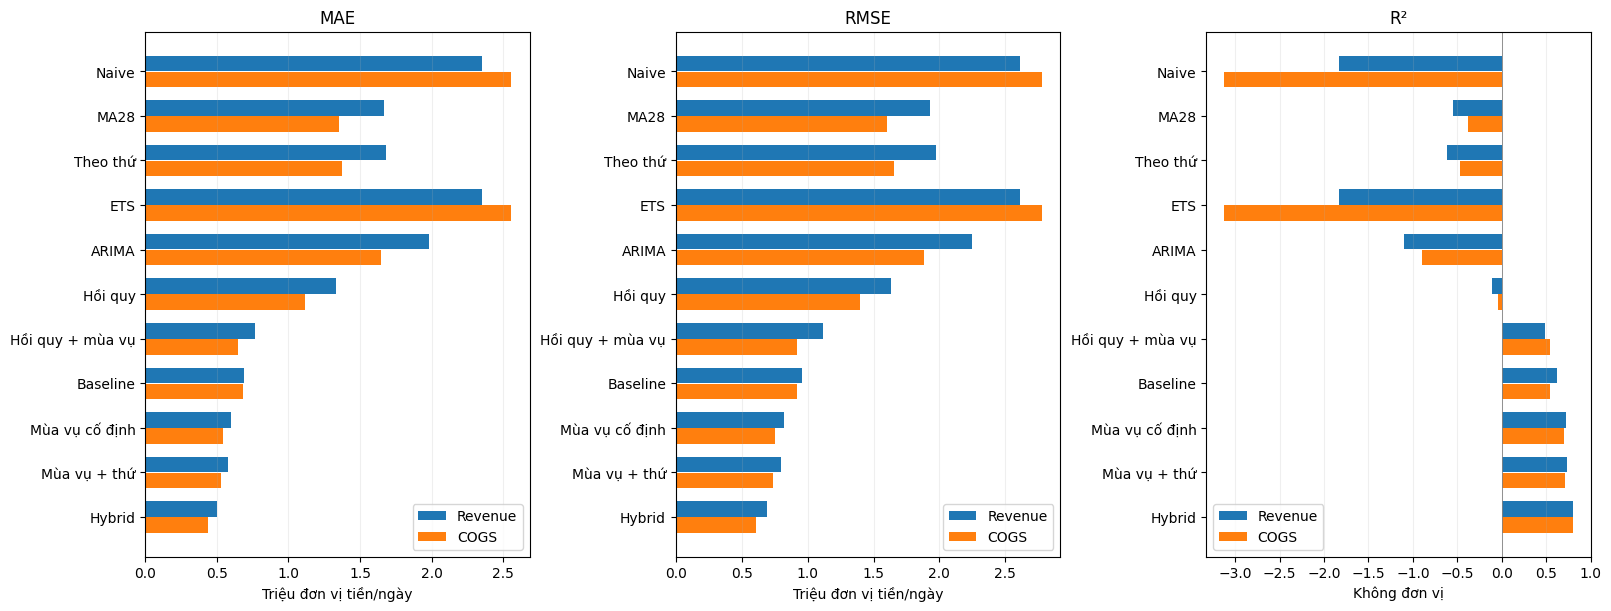

In [14]:
# Biểu đồ so sánh 11 mô hình theo từng chỉ số.
short_labels = ["Naive", "MA28", "Theo thứ", "ETS", "ARIMA", "Hồi quy", "Hồi quy + mùa vụ", "Baseline", "Mùa vụ cố định", "Mùa vụ + thứ", "Hybrid"]
fig, axes = plt.subplots(1, 3, figsize=(16, 6), layout="constrained")
positions = np.arange(len(method_order))
for ax, metric in zip(axes, ["MAE", "RMSE", "R²"]):
    for j, target in enumerate(targets):
        table = test_metrics.xs(target, level="Chỉ tiêu").reindex(method_order)
        ax.barh(positions + (j-.5)*.36, table[metric], height=.35, label=target)
    ax.set_yticks(positions, short_labels)
    ax.invert_yaxis(); ax.axvline(0, color="gray", linewidth=.6)
    ax.set_title(metric); ax.grid(axis="x", alpha=.2); ax.legend()
    ax.set_xlabel("Triệu đơn vị tiền/ngày" if metric != "R²" else "Không đơn vị")
plt.show()

### 7.5. Đối chiếu Hybrid với baseline và kết quả tốt nhất trên validation

Mức giảm dương nghĩa là Hybrid có sai số thấp hơn đối chứng trong kỳ test hồi cứu.

,Đối chứng,Chỉ tiêu,MAE đối chứng,MAE Hybrid,Giảm MAE (%),RMSE đối chứng,RMSE Hybrid,Giảm RMSE (%),R² đối chứng,R² Hybrid
0,Baseline cuộc thi,Revenue,0.690395,0.498090,27.854359,0.959012,0.692987,27.739501,0.618675,0.800888
1,Baseline cuộc thi,COGS,0.678900,0.439392,35.278895,0.923072,0.604945,34.463977,0.544235,0.804250
2,MAE validation thấp nhất,Revenue,0.576955,0.498090,13.669246,0.797846,0.692987,13.142857,0.736072,0.800888
3,MAE validation thấp nhất,COGS,0.526686,0.439392,16.574235,0.733653,0.604945,17.543462,0.712094,0.804250


Revenue | MAE validation thấp nhất: Mùa vụ mức gốc cố định + hiệu ứng thứ | MAE test thấp nhất: Hybrid Ensemble phân rã và phân khúc
COGS | MAE validation thấp nhất: Mùa vụ mức gốc cố định + hiệu ứng thứ | MAE test thấp nhất: Hybrid Ensemble phân rã và phân khúc


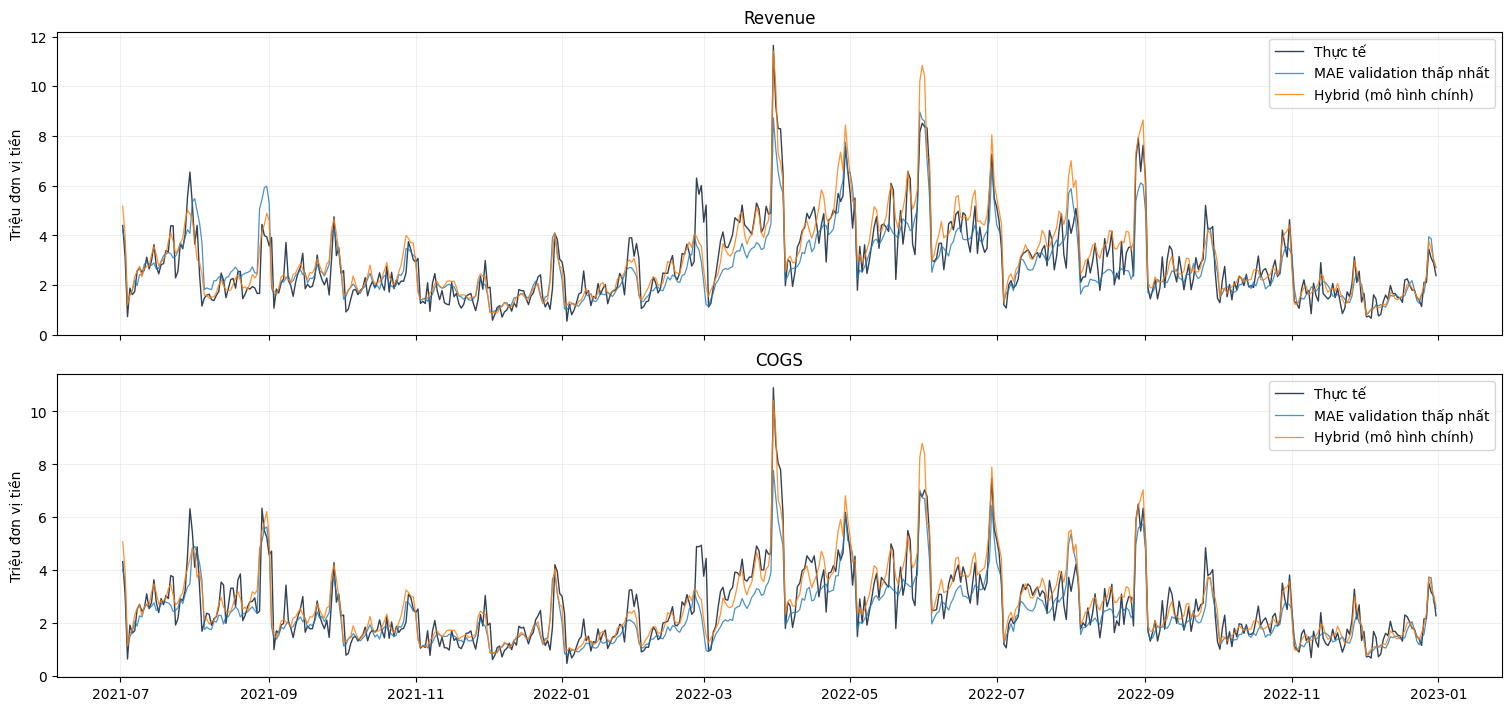

In [15]:
comparison_rows = []
for label, pred in [(contest_name, reference_test_forecast), ("MAE validation thấp nhất", validation_reference)]:
    ref = evaluate(test_actual, pred)
    new = evaluate(test_actual, hybrid_test_forecast)
    for target in targets:
        row = {"Đối chứng":label, "Chỉ tiêu":target}
        for metric in ["MAE", "RMSE"]:
            row[f"{metric} đối chứng"] = ref.loc[target, metric]
            row[f"{metric} Hybrid"] = new.loc[target, metric]
            row[f"Giảm {metric} (%)"] = 100*(1-new.loc[target,metric]/ref.loc[target,metric]) if ref.loc[target,metric] != 0 else np.nan
        row["R² đối chứng"] = ref.loc[target,"R²"]
        row["R² Hybrid"] = new.loc[target,"R²"]
        comparison_rows.append(row)
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(6))
for target in targets:
    test_best = test_metrics.xs(target, level="Chỉ tiêu").MAE.idxmin()
    print(f"{target} | MAE validation thấp nhất: {validation_best[target]} | MAE test thấp nhất: {test_best}")
fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True, layout="constrained")
for ax, target in zip(axes, targets):
    ax.plot(final_dates, test_actual[target]/1e6, label="Thực tế", color="#334155", linewidth=1)
    ax.plot(final_dates, validation_reference[target]/1e6, label="MAE validation thấp nhất", alpha=.8, linewidth=.9)
    ax.plot(final_dates, hybrid_test_forecast[target]/1e6, label="Hybrid (mô hình chính)", alpha=.85, linewidth=.9)
    ax.set_title(target); ax.set_ylabel("Triệu đơn vị tiền"); ax.legend(); ax.grid(alpha=.2)
plt.show()

### 7.6. Xuất dự báo Hybrid

`forecast_2021-07-01.csv` là đầu ra chính dành cho Streamlit. `forecast_hybrid_2021-07-01.csv` lưu cùng dự báo Hybrid theo tên riêng đã có. Cả hai gồm 548 dòng với ba cột `Date`, `Revenue`, `COGS`.

Khi chuyển sang Hybrid, notebook tự thay tệp đầu ra chính nếu nội dung hiện tại khớp dự báo đối chứng từ quy trình cũ. Nếu một tệp có nội dung khác với dự báo đã biết, ô xuất tệp sẽ yêu cầu kiểm tra tệp đó.

In [16]:
from tempfile import TemporaryDirectory

EXPORT_FORECAST = True
output_dir = project_root / "data/model/du_bao"
output_path = output_dir / f"forecast_{dev_end:%Y-%m-%d}.csv"
hybrid_output_path = output_dir / f"forecast_hybrid_{dev_end:%Y-%m-%d}.csv"

if EXPORT_FORECAST:
    csv_options = {"date_format": "%Y-%m-%d", "float_format": "%.2f", "lineterminator": "\n"}
    hybrid_csv = hybrid_test_forecast.rename_axis("Date").to_csv(**csv_options)
    previous_csv = validation_reference.rename_axis("Date").to_csv(**csv_options)
    paths_to_write = []
    for path in (output_path, hybrid_output_path):
        current_csv = path.read_text(encoding="utf-8") if path.is_file() else None
        if current_csv == hybrid_csv:
            continue
        if current_csv is not None and (path != output_path or current_csv != previous_csv):
            raise FileExistsError(
                f"Tệp đã có nội dung khác với dự báo đã biết: {path}. "
                "Hãy kiểm tra và di chuyển tệp này trước khi xuất dự báo Hybrid."
            )
        paths_to_write.append(path)

    if paths_to_write:
        output_dir.mkdir(parents=True, exist_ok=True)
        with TemporaryDirectory(dir=output_dir) as directory:
            for path in paths_to_write:
                temporary_path = Path(directory) / path.name
                temporary_path.write_bytes(hybrid_csv.encode("utf-8"))
                temporary_path.replace(path)

    for path in (output_path, hybrid_output_path):
        print(f"Đã xác nhận {len(hybrid_test_forecast)} dòng dự báo Hybrid: {path.relative_to(project_root)}")
display(hybrid_test_forecast.head().round(2))

Đã xác nhận 548 dòng dự báo Hybrid: data\model\du_bao\forecast_2021-07-01.csv
Đã xác nhận 548 dòng dự báo Hybrid: data\model\du_bao\forecast_hybrid_2021-07-01.csv


,Revenue,COGS
Date,,
2021-07-02,5175120.35,5075407.97
2021-07-03,3959283.60,3979042.62
2021-07-04,1192397.78,1150932.86
2021-07-05,1610320.21,1585438.23
2021-07-06,1801257.31,1777827.74


### 7.7. Kết luận và giới hạn

Hybrid Ensemble là mô hình dự báo chính cho Revenue và COGS. Trong kết quả thực nghiệm đã lưu, mô hình mùa vụ mức gốc cố định có hiệu ứng thứ có MAE trung bình thấp nhất trên ba lượt validation. Hybrid có MAE và RMSE thấp nhất, R² cao nhất trên 548 ngày test hồi cứu. Kết quả này mô tả các kỳ đã quan sát. Notebook 04 tiếp tục phân tích sai số và đóng góp của các thành phần Hybrid.